=============================================================
# Uric Acid Epidemiologic Analysis
# =============================================================
# Paper: Predicting 72-hour fatality in panic-level hyperuricemia:
#        Comparative evaluation of machine learning and logistic
#        regression models, a retrospective cohort study
# Authors: Hayashi R, Hayashi S, Sanayama H, et al.
# Journal: PLOS ONE (under review)
# Outputs: Fig 3A, Fig 3B, S3 Fig, S4 Fig, S6 Table
#
# Environment: Google Colaboratory (Python 3.12.13)
# See requirements.txt for library versions.
#
# NOTE: Patient data are not included in this repository.
#       Data access requests should be directed to the
#       corresponding author (hsmdfacp@jichi.ac.jp).
# =============================================================

# Serum Uric Acid and 72-Hour Fatality — Unified Analysis Notebook

**Analyses included:**
- **Part A** · UA-Stratified 72-Hour Fatality Rates (Figure 3A)
- **Part B** · Age-Stratified UA and Fatality Analysis (Supplementary Figures S3, S4; Supplementary Table S5)
- **Part C** · UA Cut-off Sensitivity Analysis (Figure 3B; Supplementary Table S6)

**Input files required (uploaded per section):**
- Part A: `UA G1 2019_dataset_LightGBM.csv` (Development), `UA G2 2018_2017 dataset_LightGBM.csv` (Validation)
- Parts B & C: `UA G1 2019_Training for Claude.csv` (Development), `UA G2 2018_2017 Validation for Claude.csv` (Validation)

**Cohort convention:** Development = 2019 cohort; Validation = 2017–2018 cohort  
**Outcome:** 72-hour in-hospital fatality (binary: 1 = death, 0 = survival)


In [1]:
# ============================================================
# Section 1: Environment Setup
# ============================================================
!pip install -q scipy pandas numpy matplotlib seaborn scikit-learn lifelines patsy openpyxl statsmodels

import os, zipfile, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, fisher_exact
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import statsmodels.api as sm
from google.colab import files
warnings.filterwarnings("ignore")

try:
    plt.style.use("seaborn-v0_8")
except OSError:
    plt.style.use("default")

try:
    from lifelines import KaplanMeierFitter
    from patsy import dmatrix
except ImportError:
    print("[WARNING] lifelines or patsy not installed — Kaplan–Meier section skipped.")

# Output directory for all generated files
OUTPUT_DIR = "/tmp/ua_fatality_outputs"
FIG_DIR    = os.path.join(OUTPUT_DIR, "figures")
TBL_DIR    = os.path.join(OUTPUT_DIR, "tables")
MANU_DIR   = os.path.join(OUTPUT_DIR, "manuscript_files")
for d in [FIG_DIR, TBL_DIR, MANU_DIR]:
    os.makedirs(d, exist_ok=True)

def save_fig(fig, filename):
    """Save figure to FIG_DIR at 300 DPI. Does NOT close the figure.
    Always call save_fig() BEFORE plt.show() to ensure the figure
    canvas is intact when saved (Colab inline backend clears figures
    after plt.show(), which would produce a blank saved file).
    """
    path = os.path.join(FIG_DIR, filename)
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"  [Figure saved] {filename}")

print("Environment ready. Output directory:", OUTPUT_DIR)


# -- Unified table output: inline display + downloadable files --------------
# CONVENTION: every analysis table must be (1) rendered inline AND
# (2) written to a downloadable file. Route all tables through export_table().
try:
    from IPython.display import display
except Exception:
    display = print
try:
    from google.colab import files as _colab_files
    _IN_COLAB = True
except Exception:
    _IN_COLAB = False

def show_table(df, caption=None):
    """Render a DataFrame inline as an HTML table (falls back to plain text)."""
    try:
        styler = df.style.set_caption(caption) if caption else df.style
        display(styler)
    except Exception:
        if caption:
            print(f"\n=== {caption} ===")
        print(df.to_string())

def export_table(obj, basename, caption=None, download=True):
    """Display inline AND save as downloadable files.
    obj : a DataFrame, or a dict {sheet_name: DataFrame} for multi-sheet output.
    Writes <basename>.xlsx (all sheets) and one .csv per sheet to TBL_DIR,
    then triggers a Colab download for each file. Returns the .xlsx path.
    """
    sheets = obj if isinstance(obj, dict) else {"Table": obj}
    for name, d in sheets.items():
        cap = caption if len(sheets) == 1 else f"{caption or basename} -- {name}"
        show_table(d, cap)
    xlsx_path = os.path.join(TBL_DIR, f"{basename}.xlsx")
    with pd.ExcelWriter(xlsx_path, engine="openpyxl") as w:
        for name, d in sheets.items():
            idx = isinstance(d.index, pd.MultiIndex) or (d.index.name is not None)
            d.to_excel(w, sheet_name=str(name)[:31], index=idx)
    csv_paths = []
    for name, d in sheets.items():
        idx = isinstance(d.index, pd.MultiIndex) or (d.index.name is not None)
        suffix = "" if len(sheets) == 1 else f"_{name}"
        cpath = os.path.join(TBL_DIR, f"{basename}{suffix}.csv")
        d.to_csv(cpath, index=idx)
        csv_paths.append(cpath)
    print(f"  [Table saved] {os.path.basename(xlsx_path)}  (+{len(csv_paths)} CSV)")
    if download and _IN_COLAB:
        for p in [xlsx_path] + csv_paths:
            _colab_files.download(p)
    return xlsx_path


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 5.9 MB/s eta 0:00:00
Environment ready. Output directory: /tmp/ua_fatality_outputs


In [2]:
# ============================================================
# Section 2: Data Loading  [UNIFIED — runs once for all parts]
# ============================================================
# Canonical input files:
#   Development cohort (2019) : UA G1 2019_Training for Claude.csv
#   Validation cohort (2017–2018): UA G2 2018_2017 Validation for Claude.csv
#
# These two files are used by Part A, Part B, and Part C.
# Upload once here; all subsequent cells reference dev_df / val_df.
# [DATA LOADING — UNCHANGED logic; filenames unified per user request]

print("Upload Development cohort CSV  →  UA G1 2019_Training for Claude.csv")
uploaded = files.upload()
dev_df = pd.read_csv(list(uploaded.keys())[0])

print("\nUpload Validation cohort CSV  →  UA G2 2018_2017 Validation for Claude.csv")
uploaded = files.upload()
val_df = pd.read_csv(list(uploaded.keys())[0])

# ── Column name constants (single source of truth) ────────────────────────
UA_COL  = "Uric acid (mg/dL)"
OUT_COL = "Outcome"
AGE_COL = "Age"
UA_TO_SI = 59.48  # mg/dL -> umol/L

# ── Basic sanity checks ───────────────────────────────────────────────────
for cname, df in [("Development", dev_df), ("Validation", val_df)]:
    print(f"\n{cname}: {df.shape[0]} patients, {df.shape[1]} columns")
    for col in [OUT_COL, UA_COL, AGE_COL]:
        status = "✓" if col in df.columns else "✗  NOT FOUND"
        print(f"  {status}  '{col}'")

print("\n[Data loading complete — dev_df and val_df available for all analyses]")

# ── Global constants (used by Part A, Section 6) ─────────────────────────
# UA stratum bin edges and display labels — defined once here for all cells.
UA_BINS   = [0.0, 10.1, 12.1, 14.1, 16.1, 50.0]   # right=False → 10.0/10.1-12.0/...
UA_LABELS = ["10.0", "10.1–12.0", "12.1–14.0", "14.1–16.0", "≥16.1"]   # mg/dL


Upload Development cohort CSV  →  UA G1 2019_Training for Claude.csv


Saving UA G1 2019_Training for Claude.csv to UA G1 2019_Training for Claude.csv

Upload Validation cohort CSV  →  UA G2 2018_2017 Validation for Claude.csv


Saving UA G2 2018_2017 Validation for Claude.csv to UA G2 2018_2017 Validation for Claude.csv

Development: 756 patients, 44 columns
  ✓  'Outcome'
  ✓  'Uric acid (mg/dL)'
  ✓  'Age'

Validation: 1243 patients, 44 columns
  ✓  'Outcome'
  ✓  'Uric acid (mg/dL)'
  ✓  'Age'

[Data loading complete — dev_df and val_df available for all analyses]


---
## Part A · UA-Stratified 72-Hour Fatality Rates

**Analysis:** 72-hour in-hospital fatality rate by uric acid stratum, comparing Development vs Validation cohorts
**Strata (mg/dL):** 10.0 / 10.1–12.0 / 12.1–14.0 / 14.1–16.0 / ≥16.1
**Statistical test:** Chi-square test per stratum (Development vs Validation)
**Output:** Figure 3A


=== Development Cohort: Fatality Rate by Stratum ===
           Death  Alive  Total  Fatality Rate  Standard Error
10.0           1     33     34         0.0294          0.0290
10.1–12.0     19    435    454         0.0419          0.0094
12.1–14.0     11    150    161         0.0683          0.0199
14.1–16.0     10     62     72         0.1389          0.0408
≥16.1          7     28     35         0.2000          0.0676
Overall       48    708    756         0.0635          0.0089

=== Validation Cohort: Fatality Rate by Stratum ===
           Death  Alive  Total  Fatality Rate  Standard Error
10.0           2     68     70         0.0286          0.0199
10.1–12.0     13    734    747         0.0174          0.0048
12.1–14.0     21    233    254         0.0827          0.0173
14.1–16.0      6     90     96         0.0625          0.0247
≥16.1         12     64     76         0.1579          0.0418
Overall       54   1189   1243         0.0434          0.0058

=== Chi-square Test (Deve

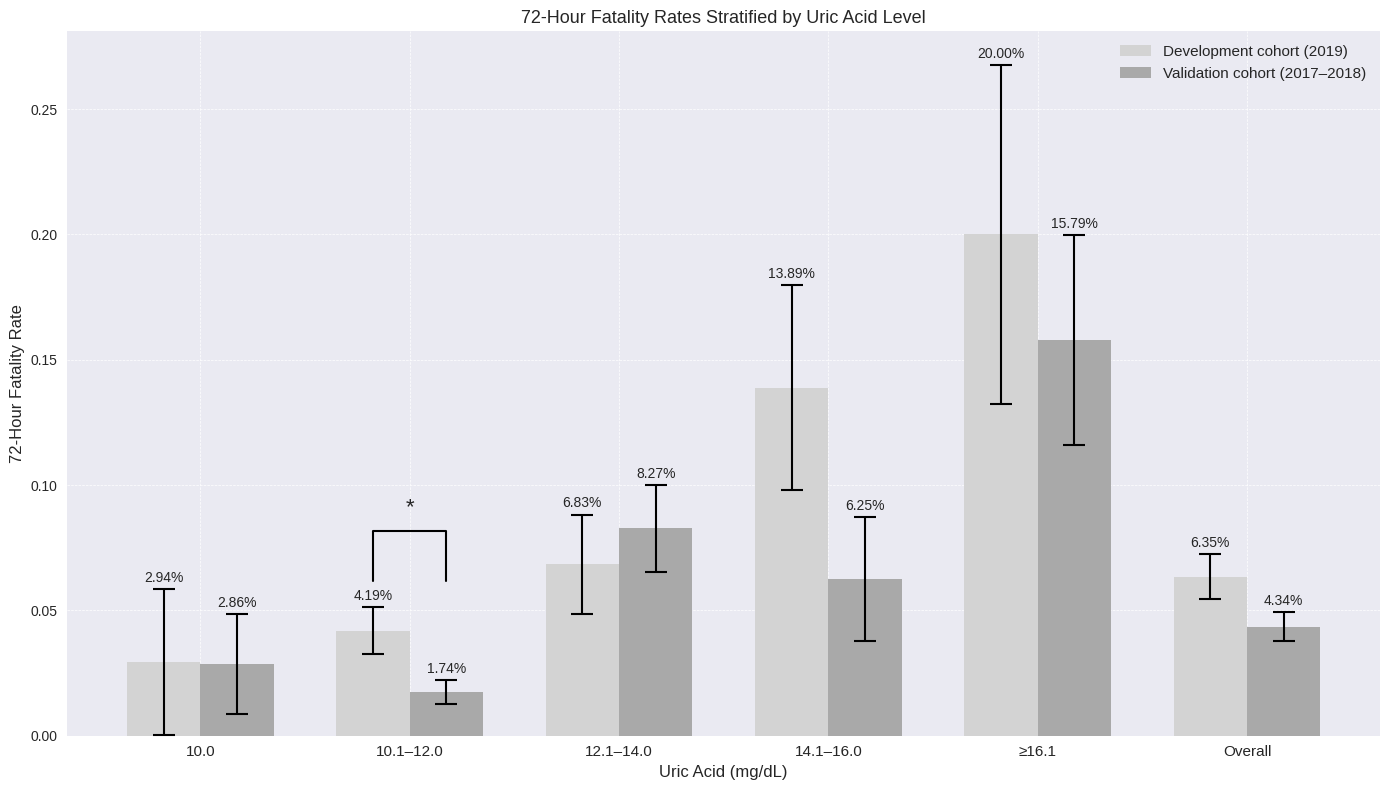

,Death,Alive,Total,Fatality Rate,Standard Error
10.0,1,33,34,0.029400,0.029000
10.1–12.0,19,435,454,0.041900,0.009400
12.1–14.0,11,150,161,0.068300,0.019900
14.1–16.0,10,62,72,0.138900,0.040800
≥16.1,7,28,35,0.200000,0.067600
Overall,48,708,756,0.063500,0.008900


,Death,Alive,Total,Fatality Rate,Standard Error
10.0,2,68,70,0.028600,0.019900
10.1–12.0,13,734,747,0.017400,0.004800
12.1–14.0,21,233,254,0.082700,0.017300
14.1–16.0,6,90,96,0.062500,0.024700
≥16.1,12,64,76,0.157900,0.041800
Overall,54,1189,1243,0.043400,0.005800


,Chi2,p-value
10.0,0.000000,1.000000
10.1–12.0,5.599000,0.017971
12.1–14.0,0.119300,0.729848
14.1–16.0,1.970200,0.160428
≥16.1,0.076200,0.782504
Overall,3.499200,0.061399


  [Table saved] TableA_UA_Stratified_Fatality.xlsx  (+3 CSV)


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# ============================================================
# Part A: UA-Stratified Fatality Rate Analysis (Figure 3A)
# ============================================================
# [FIXED] What was wrong: original code used iloc[:, 28] / iloc[:, 0] for
#         uric acid and outcome from a different CSV (LightGBM variant).
# [FIXED] What was changed: uses unified dev_df / val_df with named columns
#         UA_COL and OUT_COL, loaded once in Section 2.

# Extract series from unified DataFrames
uric_acid_train = dev_df[UA_COL].astype(float)
outcome_train   = dev_df[OUT_COL].astype(int)
uric_acid_test  = val_df[UA_COL].astype(float)
outcome_test    = val_df[OUT_COL].astype(int)

# ── Define uric acid strata ───────────────────────────────────────────────
# [FIXED] lower bin boundary: 0.0 (not 10.0) so values exactly 10.0
#         are captured with right=False instead of being assigned NaN.
bins   = UA_BINS    # defined in Section 2
labels = UA_LABELS  # defined in Section 2

train_strat = pd.cut(uric_acid_train, bins=bins, labels=labels, right=False)
test_strat  = pd.cut(uric_acid_test,  bins=bins, labels=labels, right=False)

def calc_fatality_by_stratum(outcome, stratified, label_list):
    """Return DataFrame of Death / Alive / Total / Fatality Rate / SE per stratum."""
    df = pd.DataFrame(index=label_list,
                      columns=["Death", "Alive", "Total", "Fatality Rate", "Standard Error"])
    df["Death"]  = stratified[outcome == 1].value_counts().reindex(label_list, fill_value=0)
    df["Alive"]  = stratified[outcome == 0].value_counts().reindex(label_list, fill_value=0)
    df["Total"]  = df["Death"] + df["Alive"]
    df["Fatality Rate"]   = df["Death"] / df["Total"]
    df["Standard Error"]  = np.sqrt(
        df["Fatality Rate"] * (1 - df["Fatality Rate"]) / df["Total"])
    return df

train_fr = calc_fatality_by_stratum(outcome_train, train_strat, labels)
test_fr  = calc_fatality_by_stratum(outcome_test,  test_strat,  labels)

def append_overall(fr):
    """Append an Overall row to a stratum-level fatality DataFrame."""
    ov = pd.DataFrame({
        "Death": [fr["Death"].sum()], "Alive": [fr["Alive"].sum()],
        "Total": [fr["Total"].sum()]}, index=["Overall"])
    ov["Fatality Rate"]  = ov["Death"] / ov["Total"]
    ov["Standard Error"] = np.sqrt(
        ov["Fatality Rate"] * (1 - ov["Fatality Rate"]) / ov["Total"])
    return pd.concat([fr, ov])

train_fr = append_overall(train_fr)
test_fr  = append_overall(test_fr)

# ── Chi-square test: Development vs Validation per stratum ───────────────
row_labels   = labels + ["Overall"]
chi2_results = pd.DataFrame(index=row_labels, columns=["Chi2", "p-value"])
for lbl in row_labels:
    ct = np.array([[train_fr.loc[lbl, "Death"], train_fr.loc[lbl, "Alive"]],
                   [test_fr.loc[lbl,  "Death"], test_fr.loc[lbl,  "Alive"]]])
    chi2, p, _, _ = chi2_contingency(ct)
    chi2_results.loc[lbl] = [round(chi2, 4), round(p, 6)]

print("=== Development Cohort: Fatality Rate by Stratum ===")
print(train_fr.round(4))
print("\n=== Validation Cohort: Fatality Rate by Stratum ===")
print(test_fr.round(4))
print("\n=== Chi-square Test (Development vs Validation per Stratum) ===")
print(chi2_results)

# ── Figure 3A: Grouped bar chart ─────────────────────────────────────────
x     = np.arange(len(row_labels))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 8))

# Error bars: capsize=8, capthick=1.5 produce the "エ" (I-bar) shape.
# elinewidth controls the vertical stem; capthick controls the horizontal caps.
# elinewidth and capthick must be inside error_kw (not top-level bar kwargs)
_ebkw = {"elinewidth": 1.5, "capthick": 1.5, "zorder": 3}
rects1 = ax.bar(x - width/2, train_fr["Fatality Rate"].astype(float), width,
                yerr=train_fr["Standard Error"].astype(float),
                label="Development cohort (2019)", color="lightgrey",
                capsize=8, error_kw=_ebkw)
rects2 = ax.bar(x + width/2, test_fr["Fatality Rate"].astype(float),  width,
                yerr=test_fr["Standard Error"].astype(float),
                label="Validation cohort (2017–2018)", color="darkgrey",
                capsize=8, error_kw=_ebkw)

ax.set_xticks(x)
ax.set_xticklabels(row_labels, fontsize=11)
ax.set_xlabel("Uric Acid (mg/dL)", fontsize=12)
ax.set_ylabel("72-Hour Fatality Rate", fontsize=12)
ax.set_title("72-Hour Fatality Rates Stratified by Uric Acid Level", fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, which="both", linestyle="--", linewidth=0.5)

for i, lbl in enumerate(row_labels):
    p_val = float(chi2_results.loc[lbl, "p-value"])
    if p_val < 0.05:
        y_max = max(float(train_fr.loc[lbl, "Fatality Rate"]),
                    float(test_fr.loc[lbl,  "Fatality Rate"]))
        ax.plot([x[i]-width/2, x[i]-width/2, x[i]+width/2, x[i]+width/2],
                [y_max+0.02, y_max+0.04, y_max+0.04, y_max+0.02], lw=1.5, c="black")
        ax.text(x[i], y_max+0.045, "*", ha="center", va="bottom", fontsize=16)

def autolabel(rects, fr):
    for rect, (_, row) in zip(rects, fr.iterrows()):
        h  = rect.get_height()
        se = float(row["Standard Error"])
        ax.annotate(f'{h:.2%}',
                    xy=(rect.get_x() + rect.get_width()/2, h + se + 0.01),
                    xytext=(0, -15), textcoords="offset points",
                    ha="center", va="bottom", fontsize=10)

autolabel(rects1, train_fr)
autolabel(rects2, test_fr)
fig.tight_layout()
save_fig(fig, "Figure_3A_UA_Stratified_Fatality_Rates.png")
plt.show()
plt.close(fig)

# -- Table A: inline display + downloadable files (xlsx + csv) -------------
export_table(
    {"Development": train_fr.round(4),
     "Validation":  test_fr.round(4),
     "Chi2_Results": chi2_results},
    "TableA_UA_Stratified_Fatality",
    caption="Table A. Uric acid-stratified 72-hour fatality rates",
)
# [Reproducibility] Verify: p<0.05 asterisk markers match chi2_results above.

# -- Download figure --------------------------------------------------------
if _IN_COLAB:
    files.download(os.path.join(FIG_DIR, "Figure_3A_UA_Stratified_Fatality_Rates.png"))


---
## Part B · Age-Stratified Analysis: Uric Acid vs 72-Hour Fatality

**Analysis:** UA concentration and 72-hour fatality stratified by age group (<65 / 65–74 / ≥75 years)
**Statistical tests:** Chi-square, Fisher's exact
**Data:** dev_df / val_df from Section 2 (no additional upload required)
**Outputs:** Supplementary Figure S3, Supplementary Figure S4, Supplementary Table S5



Development: 756 patients after missing-value removal
  <65: 271 (35.8%)
  65–74: 179 (23.7%)
  ≥75: 306 (40.5%)

Validation: 1243 patients after missing-value removal
  <65: 434 (34.9%)
  65–74: 293 (23.6%)
  ≥75: 516 (41.5%)

Development COHORT — Outcome by Age Group
Age Group    Alive   Death   Total    Rate%
---------------------------------------------
<65            255      16     271      5.9
65–74          169      10     179      5.6
≥75            284      22     306      7.2

Chi-square: 0.629, df=2, p=0.730227

Validation COHORT — Outcome by Age Group
Age Group    Alive   Death   Total    Rate%
---------------------------------------------
<65            422      12     434      2.8
65–74          282      11     293      3.8
≥75            485      31     516      6.0

Chi-square: 6.286, df=2, p=0.043147
  [Figure saved] Supplementary_Figure_S3_Age_Fatality_Development.png


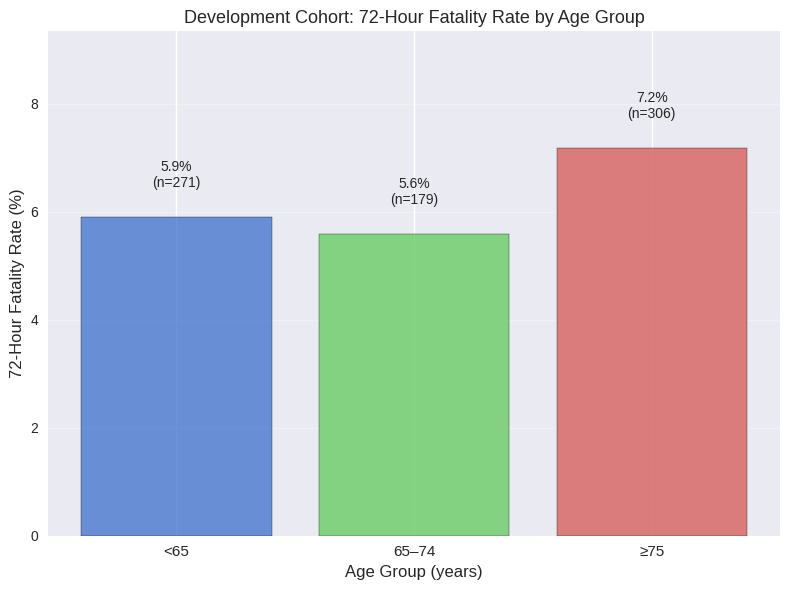

  [Figure saved] Supplementary_Figure_S3_Age_Fatality_Validation.png


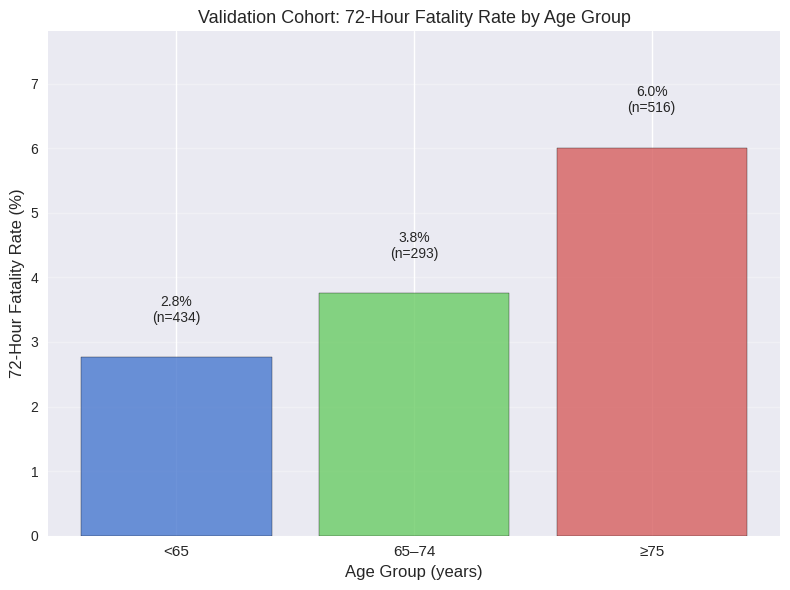

  [Figure saved] Supplementary_Figure_S4_UA_Distribution_by_Age_Development.png


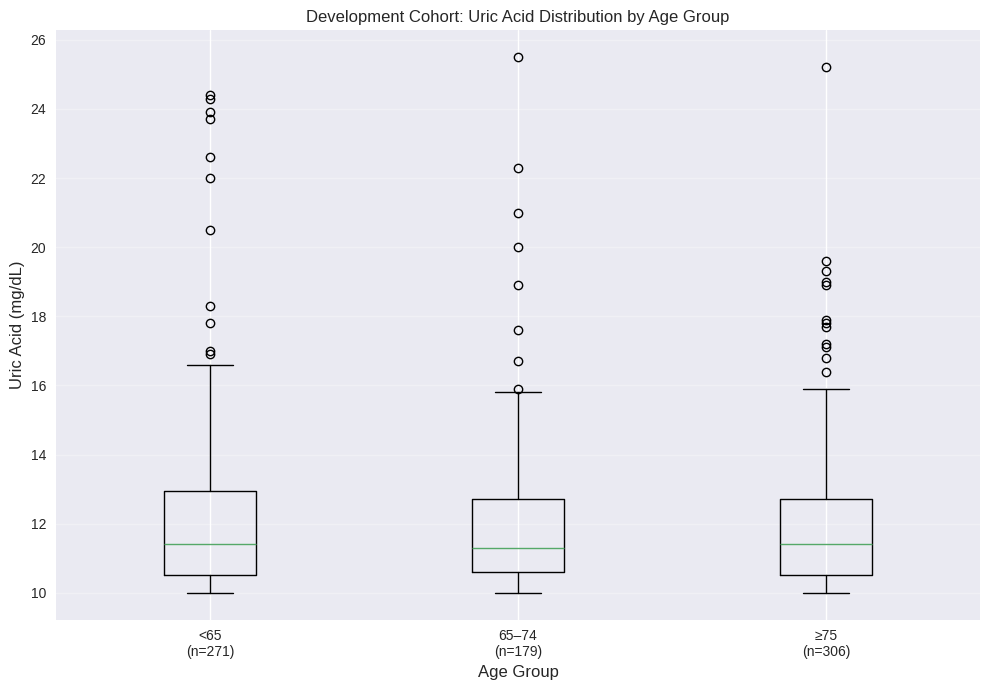

  [Figure saved] Supplementary_Figure_S4_UA_Distribution_by_Age_Validation.png


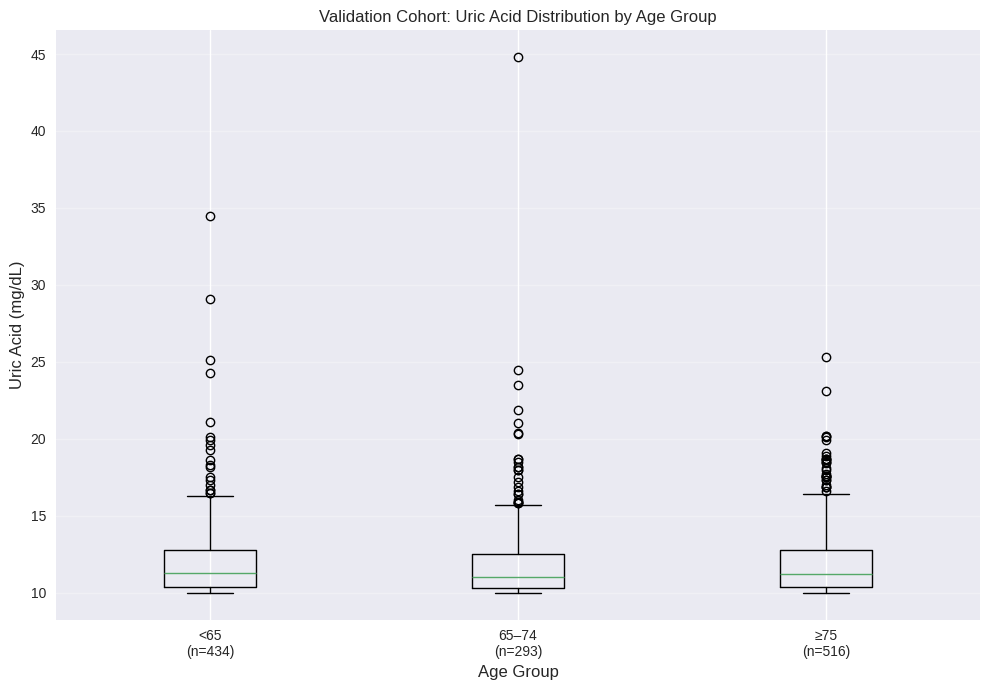

,Cohort,Age_Group,Alive,Death,Total,Death_Rate_%,Chi2,p_value
0,Development,<65,255,16,271,5.904059,0.628800,0.730227
1,Development,65–74,169,10,179,5.586592,0.628800,0.730227
2,Development,≥75,284,22,306,7.189542,0.628800,0.730227
3,Validation,<65,422,12,434,2.764977,6.286300,0.043147
4,Validation,65–74,282,11,293,3.754266,6.286300,0.043147
5,Validation,≥75,485,31,516,6.007752,6.286300,0.043147


,Cohort,Age_Group,N,UA_Mean_mgdL,UA_Median_mgdL,UA_SD_mgdL
0,Development,<65,271,12.100000,11.400000,2.500000
1,Development,65–74,179,12.000000,11.300000,2.300000
2,Development,≥75,306,12.000000,11.400000,2.000000
3,Validation,<65,434,12.000000,11.300000,2.500000
4,Validation,65–74,293,12.000000,11.000000,3.100000
5,Validation,≥75,516,12.000000,11.200000,2.200000


  [Table saved] TableS5_Age_Stratified_Fatality_UA.xlsx  (+2 CSV)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# ============================================================
# Part B: Age-Stratified Analysis  (uses dev_df / val_df from Section 2)
# ============================================================

def create_age_groups(df, cohort_name):
    """Assign age groups (18–64 / 65–74 / ≥75). Drops rows with missing values."""
    df_clean = df.dropna(subset=[AGE_COL, UA_COL, OUT_COL]).copy()
    df_clean["Age_Group"] = pd.cut(df_clean[AGE_COL],
                                   bins=[18, 65, 75, float("inf")],
                                   labels=["<65", "65–74", "≥75"],
                                   right=False)
    print(f"\n{cohort_name}: {len(df_clean)} patients after missing-value removal")
    for grp, n in df_clean["Age_Group"].value_counts().sort_index().items():
        print(f"  {grp}: {n} ({n/len(df_clean)*100:.1f}%)")
    return df_clean

derivation_clean_bc = create_age_groups(dev_df, "Development")
validation_clean_bc = create_age_groups(val_df, "Validation")

# ── Age-group × Outcome analysis ─────────────────────────────────────────
def age_outcome_analysis(df, cohort_name):
    """Chi-square test of fatality across age groups; returns summary rows."""
    print(f"\n{'='*70}")
    print(f"{cohort_name} COHORT — Outcome by Age Group")
    print("="*70)
    age_groups = ["<65", "65–74", "≥75"]
    rows = []
    for grp in age_groups:
        sub   = df[df["Age_Group"] == grp]
        alive = (sub[OUT_COL] == 0).sum()
        death = (sub[OUT_COL] == 1).sum()
        total = alive + death
        rate  = death / total * 100 if total > 0 else 0
        rows.append({"Cohort": cohort_name, "Age_Group": grp,
                     "Alive": alive, "Death": death, "Total": total, "Death_Rate_%": rate})
    ct = pd.crosstab(df["Age_Group"], df[OUT_COL])
    ct = ct.loc[(ct.sum(axis=1) > 0), (ct.sum(axis=0) > 0)]
    try:
        chi2, p, dof, _ = chi2_contingency(ct)
    except Exception:
        chi2, p, dof = np.nan, np.nan, np.nan
    print(f"{'Age Group':<10} {'Alive':>7} {'Death':>7} {'Total':>7} {'Rate%':>8}")
    print("-"*45)
    for r in rows:
        print(f"{r['Age_Group']:<10} {r['Alive']:>7} {r['Death']:>7} "
              f"{r['Total']:>7} {r['Death_Rate_%']:>8.1f}")
    print(f"\nChi-square: {chi2:.3f}, df={dof}, p={p:.6f}")
    for r in rows:
        r.update({"Chi2": round(chi2, 4), "p_value": round(p, 6)})
    return rows

deriv_age_res = age_outcome_analysis(derivation_clean_bc, "Development")
valid_age_res = age_outcome_analysis(validation_clean_bc, "Validation")

# ── Supplementary Figure S3: Fatality rate by age group ──────────────────
def plot_age_fatality(df, cohort_name):
    summary = (df.groupby("Age_Group")[OUT_COL]
                 .agg(["count", "sum", "mean"])
                 .rename(columns={"count": "N", "sum": "Deaths", "mean": "Rate"}))
    summary["Rate_%"] = summary["Rate"] * 100
    fig, ax = plt.subplots(figsize=(8, 6))
    colors = ["#4878CF", "#6ACC65", "#D65F5F"]
    bars = ax.bar(range(len(summary)), summary["Rate_%"],
                  color=colors[:len(summary)], alpha=0.8, edgecolor="black")
    ax.set_title(f"{cohort_name} Cohort: 72-Hour Fatality Rate by Age Group", fontsize=13)
    ax.set_xlabel("Age Group (years)", fontsize=12)
    ax.set_ylabel("72-Hour Fatality Rate (%)", fontsize=12)
    ax.set_xticks(range(len(summary)))
    ax.set_xticklabels(summary.index.tolist(), fontsize=11)
    ax.set_ylim(0, summary["Rate_%"].max() * 1.3)
    ax.grid(True, axis="y", alpha=0.3)
    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f"{row['Rate_%']:.1f}%\n(n={int(row['N'])})",
                ha="center", va="bottom", fontsize=10)
    fig.tight_layout()
    return fig

fig_s2_dev = plot_age_fatality(derivation_clean_bc, "Development")
save_fig(fig_s2_dev, "Supplementary_Figure_S3_Age_Fatality_Development.png")
plt.show()
plt.close(fig_s2_dev)
fig_s2_val = plot_age_fatality(validation_clean_bc, "Validation")
save_fig(fig_s2_val, "Supplementary_Figure_S3_Age_Fatality_Validation.png")
plt.show()
plt.close(fig_s2_val)

# ── Supplementary Figure S4: UA distribution by age group ────────────────
def plot_ua_distribution_by_age(df, cohort_name):
    age_groups = ["<65", "65–74", "≥75"]
    ua_data, tick_labels, stats_rows = [], [], []
    for grp in age_groups:
        sub = df[df["Age_Group"] == grp]
        if len(sub) == 0:
            continue
        ua = sub[UA_COL].dropna().values
        ua_data.append(ua)
        tick_labels.append(f"{grp}\n(n={len(sub)})")
        stats_rows.append({"Cohort": cohort_name, "Age_Group": grp, "N": len(sub),
                           "UA_Mean_mgdL": round(ua.mean(), 1),
                           "UA_Median_mgdL": round(np.median(ua), 1),
                           "UA_SD_mgdL": round(ua.std(), 1)})
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.boxplot(ua_data, labels=tick_labels)
    ax.set_xlabel("Age Group", fontsize=12)
    ax.set_ylabel("Uric Acid (mg/dL)", fontsize=12)
    ax.grid(True, axis="y", alpha=0.3)
    ax.set_title(f"{cohort_name} Cohort: Uric Acid Distribution by Age Group", fontsize=12)
    fig.tight_layout()
    return fig, pd.DataFrame(stats_rows)

fig_s3_dev, s3_stats_dev = plot_ua_distribution_by_age(derivation_clean_bc, "Development")
save_fig(fig_s3_dev, "Supplementary_Figure_S4_UA_Distribution_by_Age_Development.png")
plt.show()
plt.close(fig_s3_dev)
fig_s3_val, s3_stats_val = plot_ua_distribution_by_age(validation_clean_bc, "Validation")
save_fig(fig_s3_val, "Supplementary_Figure_S4_UA_Distribution_by_Age_Validation.png")
plt.show()
plt.close(fig_s3_val)

# -- Supplementary Table S5/S6 (age-stratified): inline + downloadable -----
s5_df = pd.DataFrame(deriv_age_res + valid_age_res)
ua_by_age = pd.concat([s3_stats_dev, s3_stats_val], ignore_index=True)
export_table(
    {"Age_Fatality_Summary": s5_df,
     "UA_Distribution_by_Age": ua_by_age},
    "TableS5_Age_Stratified_Fatality_UA",
    caption="Age-stratified fatality and uric acid concentrations",
)
# [Reproducibility] Verify: chi-square p-values match console output above.

# -- Download figures -------------------------------------------------------
if _IN_COLAB:
    for _f in ["Supplementary_Figure_S3_Age_Fatality_Development.png",
               "Supplementary_Figure_S3_Age_Fatality_Validation.png",
               "Supplementary_Figure_S4_UA_Distribution_by_Age_Development.png",
               "Supplementary_Figure_S4_UA_Distribution_by_Age_Validation.png"]:
        files.download(os.path.join(FIG_DIR, _f))


---
## Part C · Sensitivity Analysis: Uric Acid Cut-off and 72-Hour Fatality

**Analysis:** Sensitivity analysis of UA thresholds (3.0–12.0 mg/dL) for predicting 72-hour fatality
**Sub-analyses:** (1) Cut-off sensitivity, (2) Cochran–Armitage trend, (3) Low-event exclusion, (4) RCS
**Data:** dev_df / val_df from Section 2 (no additional upload required)
**Output:** Figure 3B, Supplementary Table S6


Development: 756 patients | Fatality rate = 0.063 | UA mean = 12.0 mg/dL SD = 2.3
Validation: 1243 patients | Fatality rate = 0.043 | UA mean = 12.0 mg/dL SD = 2.6

=== Cut-off Sensitivity — Development ===
 Cutoff  High_UA_N  High_UA_Deaths  High_UA_Rate  Low_UA_N  Low_UA_Deaths  Low_UA_Rate    OR  CI_Lower  CI_Upper  P_value
   11.0        459              37         0.081       297             11        0.037 2.280     1.144     4.543    0.025
   12.0        283              30         0.106       473             18        0.038 2.997     1.638     5.485    0.000

=== Cut-off Sensitivity — Validation ===
 Cutoff  High_UA_N  High_UA_Deaths  High_UA_Rate  Low_UA_N  Low_UA_Deaths  Low_UA_Rate    OR  CI_Lower  CI_Upper  P_value
   11.0        697              46         0.066       546              8        0.015 4.752     2.224    10.155      0.0
   12.0        449              39         0.087       794             15        0.019 4.940     2.691     9.068      0.0

=== Cochran–Armita

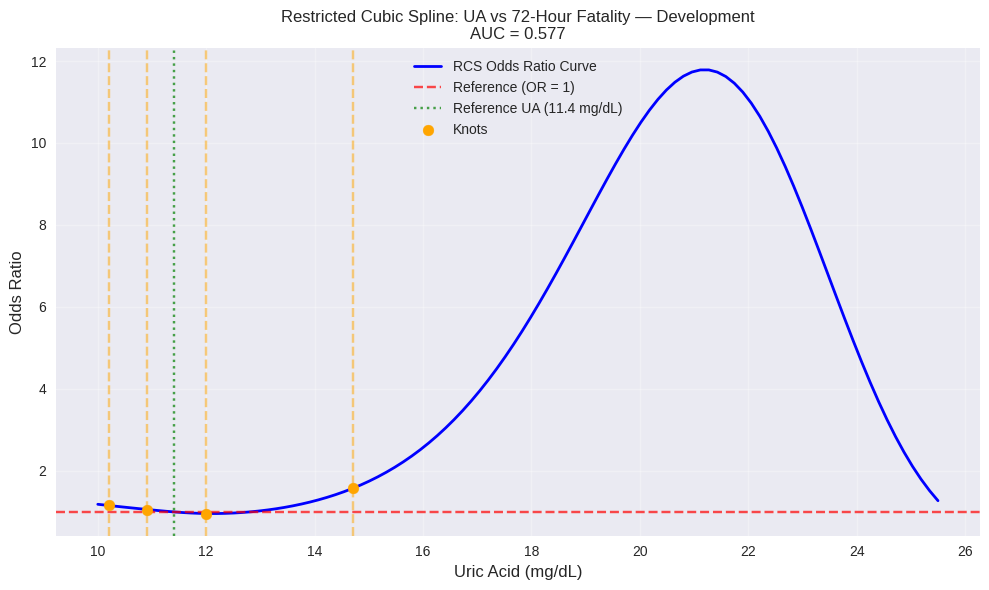


=== RCS Analysis — Validation ===
Knots (mg/dL): [10.1 10.7 11.9 15. ]
AUC: 0.697
  [Figure saved] Figure_3B_RCS_Validation.png


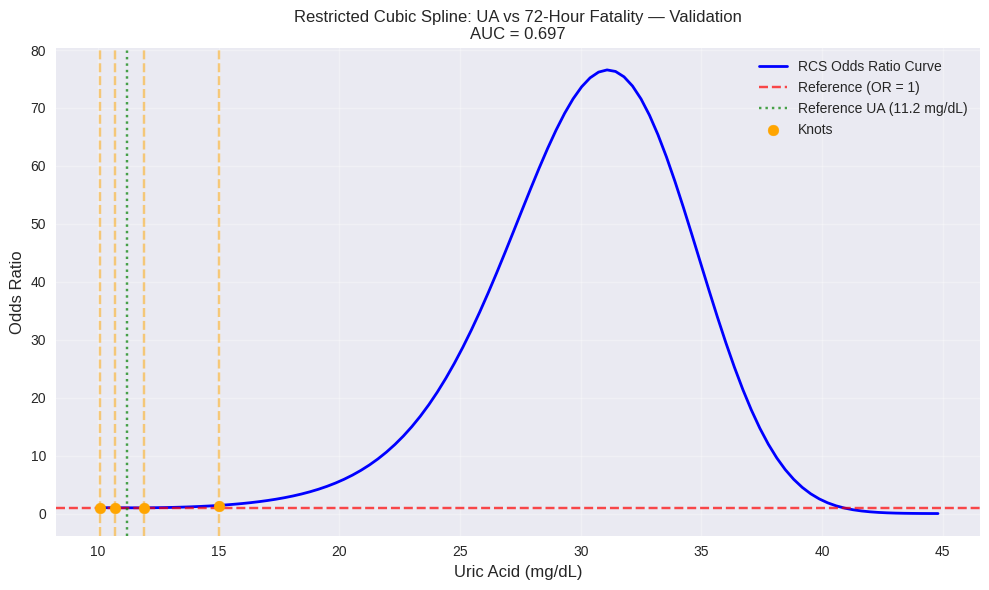


SENSITIVITY ANALYSIS SUMMARY

1. Cochran–Armitage trend:
   Dev: stat=15.400, p=0.000087
   Val: stat=29.422, p=0.000000

2. Low-event exclusion OR per mg/dL:
   Dev: 1.140 (1.009–1.288)
   Val: 1.119 (1.033–1.212)

3. RCS AUC:
   Dev: 0.577  |  Val: 0.697
[WARNING] Part A not run — PartA_UA_Stratified sheet skipped.
Development: 756 patients | Fatality rate = 0.063 | UA mean = 12.0 mg/dL SD = 2.3
Validation: 1243 patients | Fatality rate = 0.043 | UA mean = 12.0 mg/dL SD = 2.6

=== Cut-off Threshold Analysis — Development ===
     Cohort      Threshold   OR  CI_Lower  CI_Upper  P_value
Development UA ≥11.0 mg/dL 2.28      1.14      4.54 0.024651
Development UA ≥12.0 mg/dL 3.00      1.64      5.48 0.000379

=== Cut-off Threshold Analysis — Validation ===
    Cohort      Threshold   OR  CI_Lower  CI_Upper      P_value
Validation UA ≥11.0 mg/dL 4.75      2.22     10.16 1.981270e-05
Validation UA ≥12.0 mg/dL 4.94      2.69      9.07 3.760325e-08

=== Cochran-Armitage Trend Test — Develop

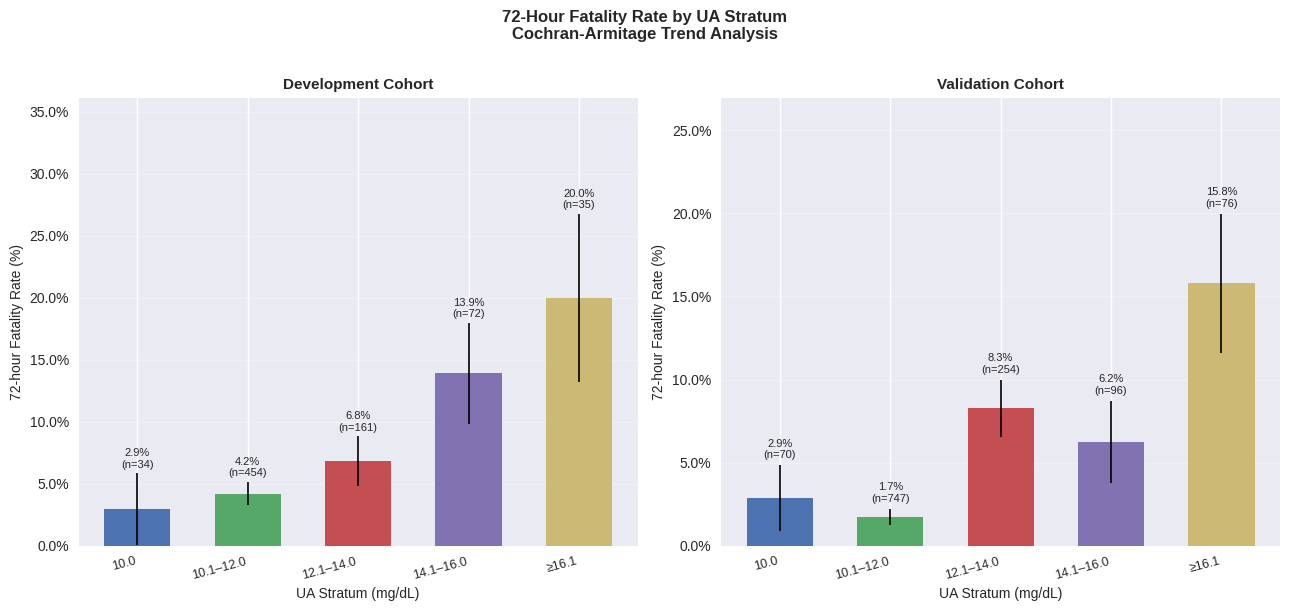

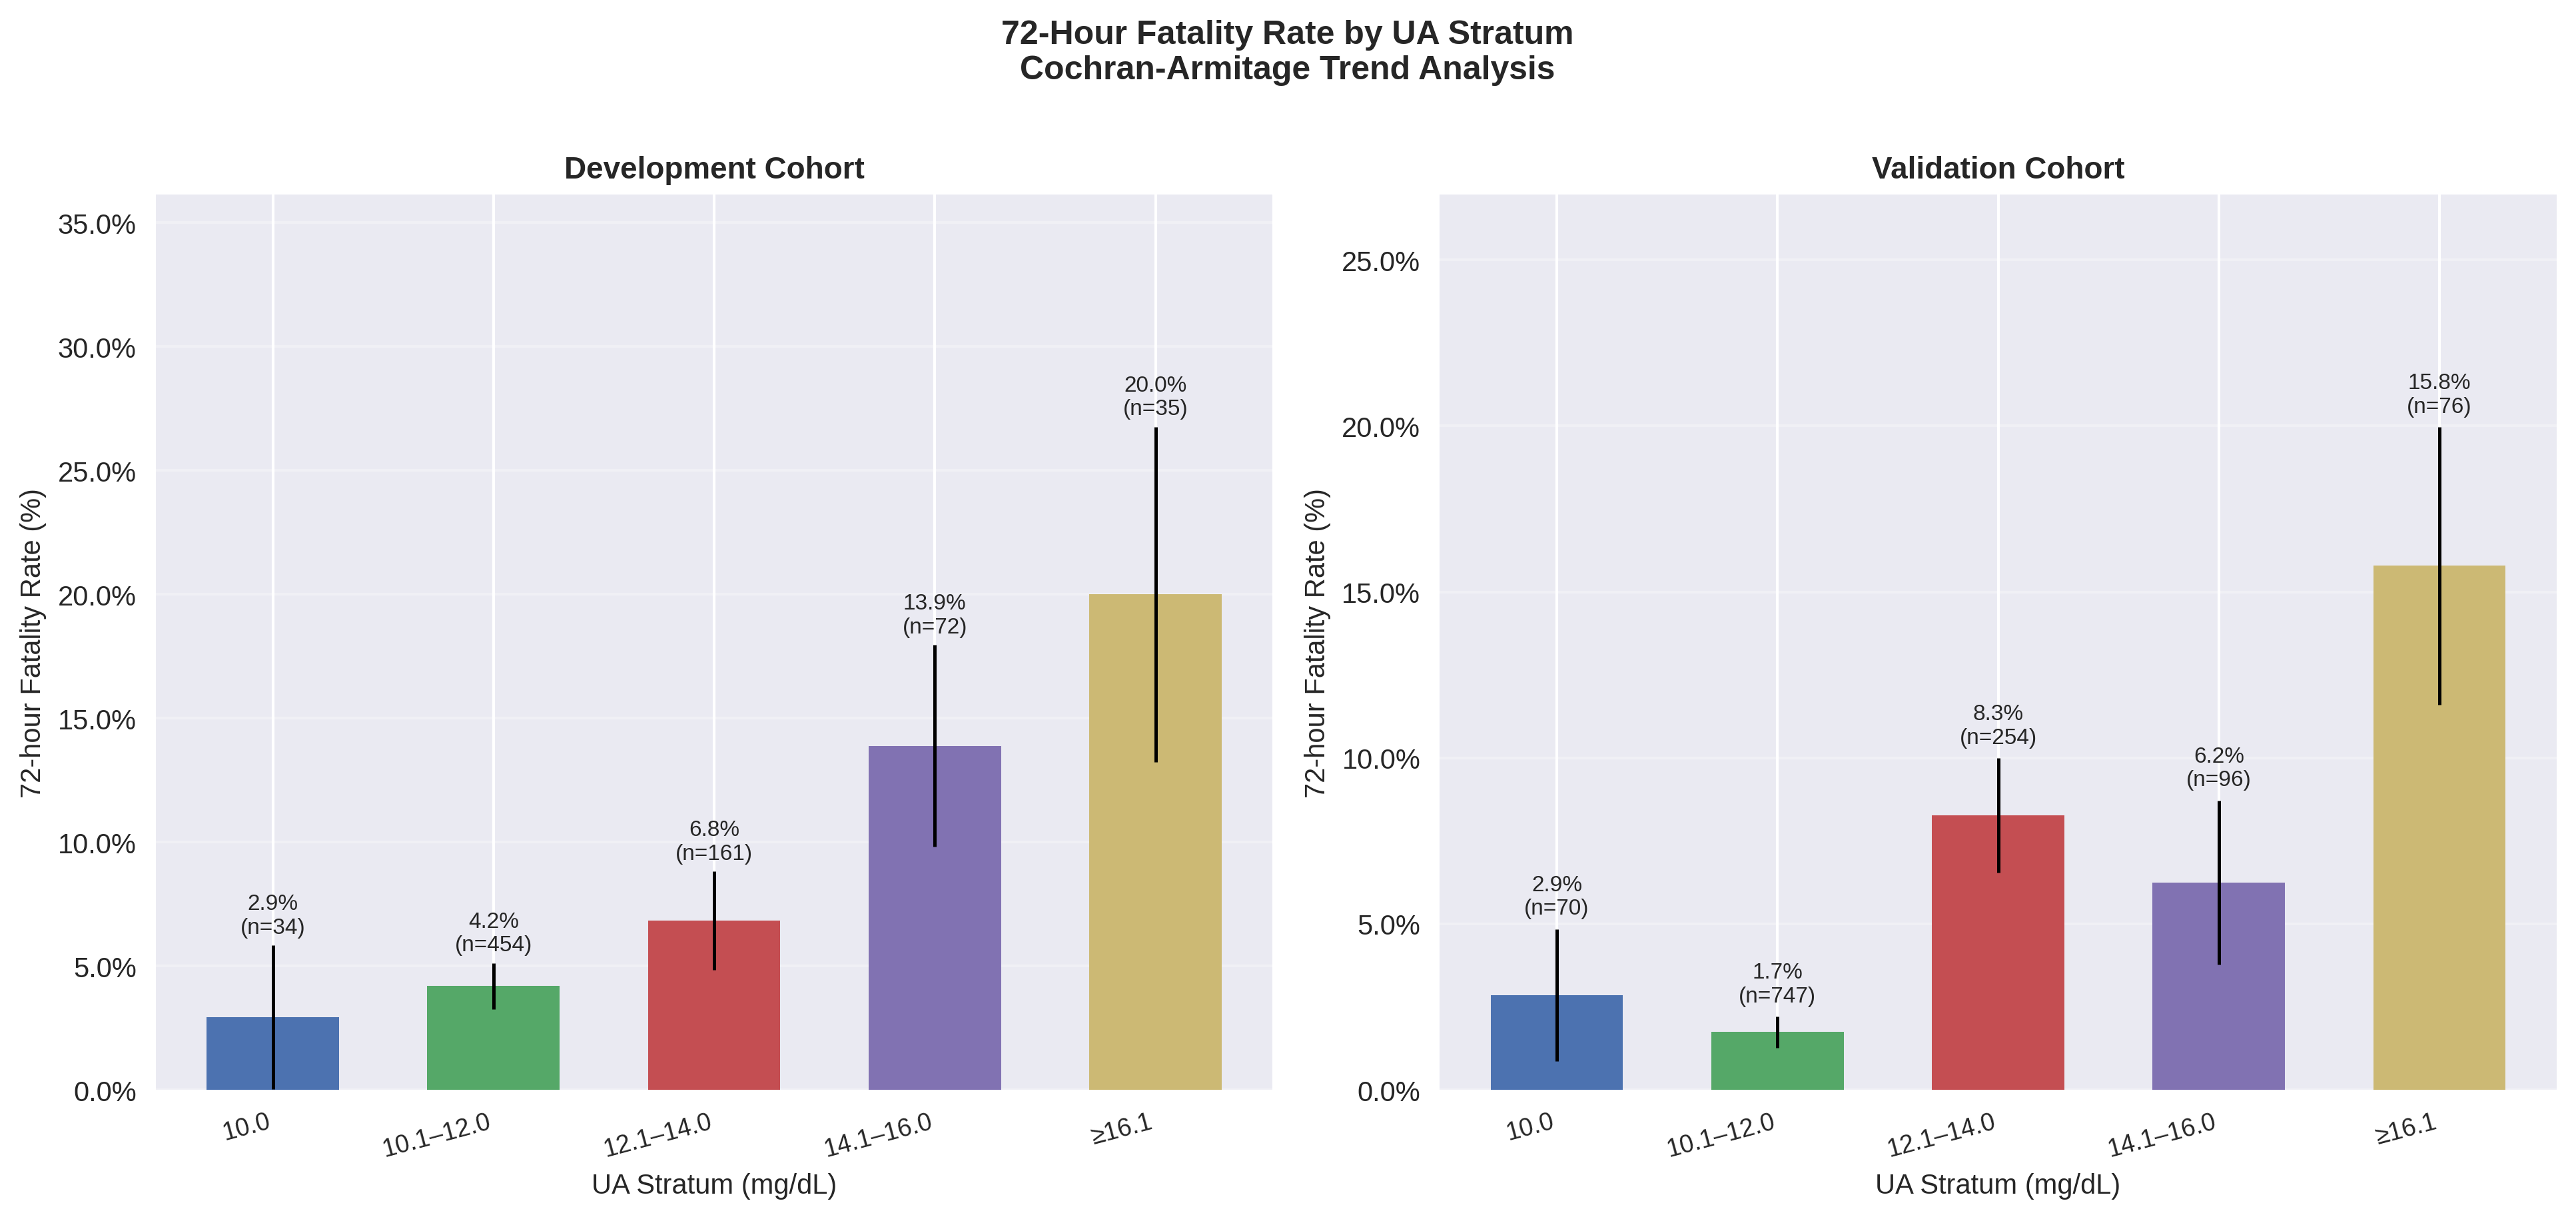

Figure saved: /content/outputs/Supp_Figure_CA_Trend.png

Exported: /content/outputs/Supplementary_Table_S6_updated.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: Table S6 (Sensitivity Analysis)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# ============================================================
# Part C: Sensitivity Analysis (reuses data from Part B)
# ============================================================

def preprocess_ua(df, cohort_name):
    """Drop rows with missing UA or Outcome; report basic stats."""
    df_clean = df.dropna(subset=[UA_COL, OUT_COL]).copy()
    print(f"{cohort_name}: {len(df_clean)} patients | "
          f"Fatality rate = {df_clean[OUT_COL].mean():.3f} | "
          f"UA mean = {df_clean[UA_COL].mean():.1f} mg/dL SD = {df_clean[UA_COL].std():.1f}")
    return df_clean

derivation_clean_c = preprocess_ua(dev_df, "Development")
validation_clean_c = preprocess_ua(val_df,  "Validation")

# ── Sensitivity Analysis 1: Cut-off Sensitivity ──────────────────────────────

def cutoff_sensitivity_analysis(df, cohort_name):
    """OR (95% CI) and p-value for UA ≥ each threshold (3–12 mg/dL)."""
    cutoffs = [3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0]
    rows = []
    for cutoff in cutoffs:
        hi = df[UA_COL] >= cutoff
        lo = ~hi
        if hi.sum() < 5 or lo.sum() < 5:
            continue
        hd = df[hi][OUT_COL].sum(); ht = hi.sum()
        ld = df[lo][OUT_COL].sum(); lt = lo.sum()
        ct = np.array([[hd, ht-hd], [ld, lt-ld]])
        if min(ct.flatten()) < 5:
            _, p = fisher_exact(ct)
        else:
            _, p, _, _ = chi2_contingency(ct)
        a, b, c, d = hd, ht-hd, ld, lt-ld
        if a > 0 and b > 0 and c > 0 and d > 0:
            or_val = (a*d)/(b*c)
            log_se = np.sqrt(1/a + 1/b + 1/c + 1/d)
            ci_lo  = np.exp(np.log(or_val) - 1.96*log_se)
            ci_hi  = np.exp(np.log(or_val) + 1.96*log_se)
        else:
            or_val = ci_lo = ci_hi = np.nan
        rows.append({"Cutoff": cutoff,
                     "High_UA_N": ht, "High_UA_Deaths": hd, "High_UA_Rate": hd/ht,
                     "Low_UA_N":  lt, "Low_UA_Deaths":  ld, "Low_UA_Rate":  ld/lt,
                     "OR": or_val, "CI_Lower": ci_lo, "CI_Upper": ci_hi, "P_value": p})
    df_res = pd.DataFrame(rows)
    print(f"\n=== Cut-off Sensitivity — {cohort_name} ===")
    print(df_res.round(3).to_string(index=False))
    return df_res

cutoff_res_dev = cutoff_sensitivity_analysis(derivation_clean_c, "Development")
cutoff_res_val = cutoff_sensitivity_analysis(validation_clean_c, "Validation")

# ── Sensitivity Analysis 2: Cochran–Armitage Trend Test ──────────────────────

def cochran_armitage_trend_test(df, cohort_name, n_categories=5):
    """Cochran–Armitage trend test across UA quintiles."""
    df2 = df.copy()
    df2["UA_quintile"] = pd.qcut(df2[UA_COL], q=n_categories, labels=False, duplicates="drop")
    cats = sorted(df2["UA_quintile"].unique())
    trend_rows = []
    for cat in cats:
        sub  = df2[df2["UA_quintile"] == cat]
        deaths = sub[OUT_COL].sum()
        n      = len(sub)
        trend_rows.append({"Category": cat+1, "UA_Mean": sub[UA_COL].mean(),
                           "N": n, "Deaths": deaths, "Rate": deaths/n})
    trend_df = pd.DataFrame(trend_rows)

    n_i    = trend_df["N"].values
    r_i    = trend_df["Deaths"].values
    scores = np.arange(1, len(cats)+1)
    N      = n_i.sum(); R = r_i.sum()
    numer     = (scores * r_i).sum() - R * (n_i * scores).sum() / N
    denom_sum = (n_i * scores).sum()
    denom_sq  = (n_i * scores**2).sum()
    denom     = R*(N-R)*(denom_sq - denom_sum**2/N) / (N*(N-1))
    if denom > 0:
        t_stat  = numer**2 / denom
        p_trend = 1 - stats.chi2.cdf(t_stat, 1)
    else:
        t_stat = p_trend = np.nan

    print(f"\n=== Cochran–Armitage Trend — {cohort_name} ===")
    print(trend_df.round(3).to_string(index=False))
    print(f"Trend statistic = {t_stat:.3f},  p-trend = {p_trend:.6f}")
    return trend_df, t_stat, p_trend

trend_res_dev = cochran_armitage_trend_test(derivation_clean_c, "Development")
trend_res_val = cochran_armitage_trend_test(validation_clean_c, "Validation")

# ── Sensitivity Analysis 3: Low-Event Quintile Exclusion ─────────────────────

def low_case_exclusion_analysis(df, cohort_name, min_events=10):
    """Exclude quintiles with < min_events deaths; fit statsmodels Logit on remainder."""
    df2 = df.copy()
    df2["UA_quintile"] = pd.qcut(df2[UA_COL], q=5, labels=False, duplicates="drop")
    qstats = []
    for q in sorted(df2["UA_quintile"].unique()):
        sub = df2[df2["UA_quintile"] == q]
        d   = sub[OUT_COL].sum()
        qstats.append({"Quintile": q+1, "N": len(sub), "Deaths": d,
                       "Rate": d/len(sub), "Include": d >= min_events})
    stats_df = pd.DataFrame(qstats)
    print(f"\n=== Low-Event Exclusion — {cohort_name} ===")
    print(stats_df.round(3).to_string(index=False))
    included_q = stats_df[stats_df["Include"]]["Quintile"] - 1
    df_f = df2[df2["UA_quintile"].isin(included_q)].copy()
    print(f"After exclusion: {len(df_f)} / {len(df)} patients retained")
    if len(df_f) < 50:
        return df_f, stats_df, np.nan, np.nan, np.nan
    X = sm.add_constant(df_f[UA_COL].values)
    model = sm.Logit(df_f[OUT_COL].values, X).fit(disp=0)
    coef, se  = model.params[1], model.bse[1]
    or_u = np.exp(coef)
    ci_l = np.exp(coef - 1.96*se)
    ci_h = np.exp(coef + 1.96*se)
    p_val = model.pvalues[1]  # Wald p-value for UA coefficient
    p_str = "<0.001" if p_val < 0.001 else f"{p_val:.3f}"
    print(f"OR per mg/dL: {or_u:.3f} (95% CI: {ci_l:.3f}–{ci_h:.3f}), p={p_str}")
    return df_f, stats_df, or_u, ci_l, ci_h, p_val

excl_res_dev = low_case_exclusion_analysis(derivation_clean_c, "Development")
excl_res_val = low_case_exclusion_analysis(validation_clean_c, "Validation")

# ── Sensitivity Analysis 4: Restricted Cubic Spline (Figure 3B) ─────────────

def restricted_cubic_spline_analysis(df, cohort_name, n_knots=4):
    """
    Logistic regression with truncated-power RCS basis; plots OR curve (Figure 3B).
    Model is fit on mg/dL (unchanged; preserves AUC and L2 regularization behavior);
    axes and annotations are displayed in conventional units (mg/dL).
    Solver: liblinear (unchanged from original).
    """
    df_c = df.dropna(subset=[UA_COL, OUT_COL]).copy()
    ua   = df_c[UA_COL].values                      # mg/dL — fit scale unchanged
    knot_q = np.linspace(0.1, 0.9, n_knots)
    knots  = np.quantile(ua, knot_q)
    print(f"\n=== RCS Analysis — {cohort_name} ===")
    print(f"Knots (mg/dL): {knots.round(1)}")

    def make_features(x_arr, knots):
        feats = [x_arr]
        for k in knots[1:-1]:
            feats.append(np.maximum(0, x_arr - k)**3)
        return np.column_stack(feats)

    X_tr = make_features(ua, knots)
    y    = df_c[OUT_COL].values
    lr = LogisticRegression(max_iter=1000, solver="liblinear")
    lr.fit(X_tr, y)

    ua_range  = np.linspace(ua.min(), ua.max(), 100)          # mg/dL
    prob_pred = lr.predict_proba(make_features(ua_range, knots))[:, 1]
    odds      = prob_pred / (1 - prob_pred)
    ref_idx   = np.argmin(np.abs(ua_range - np.median(ua)))
    or_curve  = odds / odds[ref_idx]
    auc       = roc_auc_score(y, lr.predict_proba(X_tr)[:, 1])
    print(f"AUC: {auc:.3f}")                                   # unchanged

    ua_range_si = ua_range                                     # display in mg/dL
    knots_si    = knots
    median_si   = np.median(ua)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(ua_range_si, or_curve, "b-", lw=2, label="RCS Odds Ratio Curve")
    ax.axhline(1, color="red", ls="--", alpha=0.7, label="Reference (OR = 1)")
    ax.axvline(median_si, color="green", ls=":", alpha=0.7,
               label=f"Reference UA ({median_si:.1f} mg/dL)")
    knot_ors = []
    for k in knots:
        knot_ors.append(or_curve[np.argmin(np.abs(ua_range - k))])
    for k_si in knots_si:
        ax.axvline(k_si, color="orange", ls="--", alpha=0.5)
    ax.scatter(knots_si, knot_ors, color="orange", s=60, zorder=5, label="Knots")
    ax.set_xlabel("Uric Acid (mg/dL)", fontsize=12)
    ax.set_ylabel("Odds Ratio", fontsize=12)
    ax.set_title(
        f"Restricted Cubic Spline: UA vs 72-Hour Fatality — {cohort_name}\n"
        f"AUC = {auc:.3f}",
        fontsize=12
    )
    ax.legend(); ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, ua_range_si, or_curve, auc, knots_si          # mg/dL for Part E

fig_3b_dev, ua_rng_d, or_crv_d, auc_d, knots_d = restricted_cubic_spline_analysis(
    derivation_clean_c, "Development")
save_fig(fig_3b_dev, "Figure_3B_RCS_Development.png")
plt.show()
plt.close(fig_3b_dev)

fig_3b_val, ua_rng_v, or_crv_v, auc_v, knots_v = restricted_cubic_spline_analysis(
    validation_clean_c, "Validation")
save_fig(fig_3b_val, "Figure_3B_RCS_Validation.png")
plt.show()
plt.close(fig_3b_val)

# ── Summary ───────────────────────────────────────────────────────────────────
print("\n" + "="*70)
print("SENSITIVITY ANALYSIS SUMMARY")
print("="*70)
print(f"\n1. Cochran–Armitage trend:")
print(f"   Dev: stat={trend_res_dev[1]:.3f}, p={trend_res_dev[2]:.6f}")
print(f"   Val: stat={trend_res_val[1]:.3f}, p={trend_res_val[2]:.6f}")
print(f"\n2. Low-event exclusion OR per mg/dL:")
print(f"   Dev: {excl_res_dev[2]:.3f} ({excl_res_dev[3]:.3f}–{excl_res_dev[4]:.3f})")
print(f"   Val: {excl_res_val[2]:.3f} ({excl_res_val[3]:.3f}–{excl_res_val[4]:.3f})")
print(f"\n3. RCS AUC:")
print(f"   Dev: {auc_d:.3f}  |  Val: {auc_v:.3f}")

# [Reproducibility] Verify: trend p-values, OR per mg/dL, and AUC match summary above.

# ── Export Supplementary Table S6 (self-contained within Part C) ─────────
# All required variables (cutoff_res_dev/val, trend_res_dev/val,
# excl_res_dev/val, ua_rng_d/v, or_crv_d/v, auc_d/v, knots_d/v)
# are defined earlier in this same cell.

tbl_s6_path = os.path.join(TBL_DIR, "TableS6_Sensitivity_Analysis_Results.xlsx")

# labels / UA_LABELS defined in Section 2; train_fr/test_fr/chi2_results in Part A.
# If Part A was skipped, TableS6 Part A will be omitted gracefully.
_have_part_a = all(v in dir() for v in ["train_fr", "test_fr", "chi2_results"])

with pd.ExcelWriter(tbl_s6_path, engine="openpyxl") as writer:

    # ── Part A rows (UA-stratified fatality) — requires Part A ───────────
    if _have_part_a:
        part_a_rows = []
        for lbl in UA_LABELS + ["Overall"]:
            for cohort, fr in [("Development", train_fr), ("Validation", test_fr)]:
                part_a_rows.append({
                    "UA_Stratum_mgdL": lbl,
                    "Cohort":          cohort,
                    "Deaths_n":        int(fr.loc[lbl, "Death"]),
                    "Survivors_n":     int(fr.loc[lbl, "Alive"]),
                    "Total_n":         int(fr.loc[lbl, "Total"]),
                    "Fatality_Rate_%": round(float(fr.loc[lbl, "Fatality Rate"]) * 100, 1),
                    "SE_%":            round(float(fr.loc[lbl, "Standard Error"]) * 100, 2),
                    "Chi2":            round(float(chi2_results.loc[lbl, "Chi2"]), 3),
                    "P_value":         round(float(chi2_results.loc[lbl, "p-value"]), 3),
                    "Significance":    "*" if float(chi2_results.loc[lbl, "p-value"]) < 0.05 else "NS",
                })
        pd.DataFrame(part_a_rows).to_excel(writer, sheet_name="PartA_UA_Stratified", index=False)
    else:
        print("[WARNING] Part A not run — PartA_UA_Stratified sheet skipped.")

    # ── Part B: Cutoff threshold (UA≥11, UA≥12 only) ─────────────────────
    ref_cutoffs = [11.0, 12.0]
    part_b_rows = []
    for cohort, df_cut in [("Development", cutoff_res_dev), ("Validation", cutoff_res_val)]:
        for c in ref_cutoffs:
            row = df_cut[df_cut["Cutoff"] == c]
            if not row.empty:
                r = row.iloc[0]
                part_b_rows.append({
                    "Cohort":       cohort,
                    "Threshold":    f"UA ≥{c:.1f} mg/dL",
                    "OR":           round(r["OR"], 2),
                    "CI_Lower":     round(r["CI_Lower"], 2),
                    "CI_Upper":     round(r["CI_Upper"], 2),
                    "95%_CI":       f"{r['CI_Lower']:.2f}–{r['CI_Upper']:.2f}",
                    "P_value":      round(r["P_value"], 3),
                    "Significance": "<0.001" if r["P_value"] < 0.001 else f"{r['P_value']:.3f}",
                })
    pd.DataFrame(part_b_rows).to_excel(writer, sheet_name="PartB_Cutoff_Manuscript", index=False)
    cutoff_res_dev.round(4).to_excel(writer, sheet_name="PartB_Cutoff_Full_Dev", index=False)
    cutoff_res_val.round(4).to_excel(writer, sheet_name="PartB_Cutoff_Full_Val", index=False)

    # ============================================================
# Part C: Sensitivity Analysis — Cochran-Armitage (REVISED)
# Uses predefined 5 UA strata (not quintiles)
# Strata: 10.0 / 10.1-12.0 / 12.1-14.0 / 14.1-16.0 / ≥16.1
# ============================================================

import os
import statsmodels.api as sm
from scipy.stats import chi2_contingency, fisher_exact
from IPython.display import display, Image as IPImage
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from google.colab import files

OUTPUT_DIR = "/content/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Stratum definitions (single source of truth) ─────────────────────────
# [FIXED] Replaced pd.qcut quintiles with predefined clinical strata
# consistent with Table S6 Part A and Methods §8.4.1
UA_BINS_C   = [0.0, 10.1, 12.1, 14.1, 16.1, 50.0]  # right=False
UA_LABELS_C = ["10.0", "10.1–12.0", "12.1–14.0", "14.1–16.0", "≥16.1"]
STRATUM_SCORES = [1, 2, 3, 4, 5]  # ordinal scores for trend test

def preprocess_ua(df, cohort_name):
    df_clean = df.dropna(subset=[UA_COL, OUT_COL]).copy()
    print(f"{cohort_name}: {len(df_clean)} patients | "
          f"Fatality rate = {df_clean[OUT_COL].mean():.3f} | "
          f"UA mean = {df_clean[UA_COL].mean():.1f} mg/dL SD = {df_clean[UA_COL].std():.1f}")
    return df_clean

derivation_clean_c = preprocess_ua(dev_df, "Development")
validation_clean_c = preprocess_ua(val_df,  "Validation")

# ── Sensitivity Analysis 1: Cut-off Threshold (≥11.0, ≥12.0 only) ────────
# [FIXED] Removed thresholds 3.0–9.0 mg/dL (below study inclusion criterion ≥10.0)
# [FIXED] Removed ≥13.0, ≥14.0 (not present in Supplementary Table S6 Part B)

def cutoff_sensitivity_analysis(df, cohort_name):
    cutoffs = [11.0, 12.0]  # Prespecified thresholds per Methods §8.4.1
    rows = []
    for cutoff in cutoffs:
        hi = df[UA_COL] >= cutoff
        lo = ~hi
        hd = df[hi][OUT_COL].sum(); ht = hi.sum()
        ld = df[lo][OUT_COL].sum(); lt = lo.sum()
        ct = np.array([[hd, ht-hd], [ld, lt-ld]])
        if min(ct.flatten()) < 5:
            _, p = fisher_exact(ct)
        else:
            _, p, _, _ = chi2_contingency(ct)
        if all(x > 0 for x in [hd, ht-hd, ld, lt-ld]):
            or_val = (hd*(lt-ld)) / ((ht-hd)*ld)
            log_se = np.sqrt(1/hd + 1/(ht-hd) + 1/ld + 1/(lt-ld))
            ci_lo  = np.exp(np.log(or_val) - 1.96*log_se)
            ci_hi  = np.exp(np.log(or_val) + 1.96*log_se)
        else:
            or_val = ci_lo = ci_hi = np.nan
        rows.append({"Cohort": cohort_name,
                     "Threshold": f"UA ≥{cutoff:.1f} mg/dL",
                     "OR": round(or_val, 2),
                     "CI_Lower": round(ci_lo, 2),
                     "CI_Upper": round(ci_hi, 2),
                     "P_value": p})
    df_res = pd.DataFrame(rows)
    print(f"\n=== Cut-off Threshold Analysis — {cohort_name} ===")
    print(df_res.to_string(index=False))
    return df_res

cutoff_res_dev = cutoff_sensitivity_analysis(derivation_clean_c, "Development")
cutoff_res_val = cutoff_sensitivity_analysis(validation_clean_c, "Validation")

# ── Sensitivity Analysis 2: Cochran-Armitage Trend Test ──────────────────
# [FIXED] Uses predefined 5 UA strata (UA_LABELS_C) instead of quintiles
# Ordinal scores 1-5 assigned to strata for linear trend assessment

def cochran_armitage_trend_test(df, cohort_name):
    """
    Cochran-Armitage trend test across predefined UA strata.
    Formula: Z² = [Σ s_i(d_i - n_i*p̄)]² / [p̄(1-p̄) * Σ n_i(s_i - s̄)²]
    where s_i = stratum score, d_i = deaths, n_i = total, p̄ = overall rate
    """
    df2 = df.copy()
    df2["UA_stratum"] = pd.cut(df2[UA_COL],
                                bins=UA_BINS_C,
                                labels=UA_LABELS_C,
                                right=False)
    df2 = df2.dropna(subset=["UA_stratum"])

    strata_stats = []
    for lbl, score in zip(UA_LABELS_C, STRATUM_SCORES):
        sub    = df2[df2["UA_stratum"] == lbl]
        n_i    = len(sub)
        d_i    = sub[OUT_COL].sum()
        strata_stats.append({"stratum": lbl, "score": score,
                              "n": n_i, "deaths": d_i})

    stats_df = pd.DataFrame(strata_stats)
    N        = stats_df["n"].sum()
    D        = stats_df["deaths"].sum()
    p_bar    = D / N
    s_bar    = (stats_df["score"] * stats_df["n"]).sum() / N

    # Cochran-Armitage statistic
    numerator   = (stats_df["score"] * (stats_df["deaths"] - stats_df["n"] * p_bar)).sum()
    denominator = np.sqrt(p_bar * (1 - p_bar) *
                          (stats_df["n"] * (stats_df["score"] - s_bar)**2).sum())
    Z  = numerator / denominator
    Z2 = Z**2
    p_val = 1 - __import__('scipy.stats', fromlist=['chi2']).chi2.cdf(Z2, df=1)

    print(f"\n=== Cochran-Armitage Trend Test — {cohort_name} ===")
    print(stats_df.to_string(index=False))
    print(f"\nTrend Statistic (Z²): {Z2:.2f}")
    p_str = f"{p_val:.3f}" if p_val >= 0.001 else "<0.001"
    print(f"P Value: {p_str}")
    return {"Cohort": cohort_name, "Trend_Statistic": round(Z2, 2), "P_Value": p_str}

ca_dev = cochran_armitage_trend_test(derivation_clean_c, "Development")
ca_val = cochran_armitage_trend_test(validation_clean_c, "Validation")
ca_results = pd.DataFrame([ca_dev, ca_val])
print("\n=== Summary: Cochran-Armitage Results ===")
print(ca_results.to_string(index=False))

# ── Sensitivity Analysis 3: Low-Event-Rate Exclusion ─────────────────────

def low_event_exclusion_analysis(df, cohort_name, min_events=10):
    """OR per mg/dL UA after excluding strata with < min_events deaths."""
    df2 = df.copy()
    df2["UA_stratum"] = pd.cut(df2[UA_COL],
                                bins=UA_BINS_C,
                                labels=UA_LABELS_C,
                                right=False)
    strata_deaths = df2.groupby("UA_stratum")[OUT_COL].sum()
    valid_strata  = strata_deaths[strata_deaths >= min_events].index
    df_filtered   = df2[df2["UA_stratum"].isin(valid_strata)].copy()

    print(f"\n=== Low-Event Exclusion — {cohort_name} ===")
    print(f"Strata with ≥{min_events} events: {list(valid_strata)}")
    print(f"Patients retained: {len(df_filtered)} / {len(df2)}")

    X = sm.add_constant(df_filtered[UA_COL])
    y = df_filtered[OUT_COL]
    model = sm.Logit(y, X).fit(disp=False)
    coef  = model.params[UA_COL]
    se    = model.bse[UA_COL]
    or_val  = np.exp(coef)
    ci_lo   = np.exp(coef - 1.96*se)
    ci_hi   = np.exp(coef + 1.96*se)
    p_val   = model.pvalues[UA_COL]
    p_str   = f"{p_val:.3f}" if p_val >= 0.001 else "<0.001"

    print(f"OR per mg/dL: {or_val:.3f} (95% CI: {ci_lo:.3f}–{ci_hi:.3f}), P={p_str}")
    return {"Cohort": cohort_name,
            "OR_per_mgdL": round(or_val, 3),
            "CI_Lower": round(ci_lo, 3),
            "CI_Upper": round(ci_hi, 3),
            "P_Value": p_str}

lee_dev = low_event_exclusion_analysis(derivation_clean_c, "Development")
lee_val = low_event_exclusion_analysis(validation_clean_c, "Validation")
lee_results = pd.DataFrame([lee_dev, lee_val])

# ── Figure: Cochran-Armitage Bar Chart ───────────────────────────────────

def plot_ca_trend(df, cohort_name, ax):
    """Bar chart of fatality rate by UA stratum with trend annotation."""
    df2 = df.copy()
    df2["UA_stratum"] = pd.cut(df2[UA_COL],
                                bins=UA_BINS_C,
                                labels=UA_LABELS_C,
                                right=False)
    summary = df2.groupby("UA_stratum", observed=True)[OUT_COL].agg(
        Deaths="sum", Total="count").reset_index()
    summary["Rate_%"] = summary["Deaths"] / summary["Total"] * 100
    summary["SE_%"]   = np.sqrt(
        summary["Rate_%"]/100 * (1 - summary["Rate_%"]/100) / summary["Total"]) * 100

    colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]
    bars   = ax.bar(range(len(UA_LABELS_C)), summary["Rate_%"],
                    color=colors, width=0.6, zorder=2)
    ax.errorbar(range(len(UA_LABELS_C)), summary["Rate_%"],
                yerr=summary["SE_%"], fmt="none",
                color="black", capsize=4, linewidth=1.2, zorder=3)

    # Annotate bars
    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + row["SE_%"] + 0.3,
                f"{row['Rate_%']:.1f}%\n(n={int(row['Total'])})",
                ha="center", va="bottom", fontsize=8)

    ax.set_xticks(range(len(UA_LABELS_C)))
    ax.set_xticklabels(UA_LABELS_C, rotation=15, ha="right", fontsize=9)
    ax.set_xlabel("UA Stratum (mg/dL)", fontsize=10)
    ax.set_ylabel("72-hour Fatality Rate (%)", fontsize=10)
    ax.set_title(cohort_name, fontsize=11, fontweight="bold")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=1))
    ax.grid(axis="y", alpha=0.3, zorder=1)
    ax.set_ylim(0, max(summary["Rate_%"] + summary["SE_%"]) * 1.35)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
plot_ca_trend(derivation_clean_c, "Development Cohort", axes[0])
plot_ca_trend(validation_clean_c, "Validation Cohort",  axes[1])
plt.suptitle("72-Hour Fatality Rate by UA Stratum\nCochran-Armitage Trend Analysis",
             fontsize=12, fontweight="bold", y=1.01)
plt.tight_layout()

# ── Save figure ───────────────────────────────────────────────────────────
fig_path = f"{OUTPUT_DIR}/Supp_Figure_CA_Trend.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
display(IPImage(fig_path))  # Inline display in Colab
print(f"Figure saved: {fig_path}")

# ── Export Supplementary Table S6 (updated) ──────────────────────────────
wb = openpyxl.Workbook()
ws = wb.active
ws.title = "Table S6"

def thin_border():
    s = Side(style="thin")
    return Border(left=s, right=s, top=s, bottom=s)

HDR_FILL = PatternFill("solid", start_color="1F4E79", end_color="1F4E79")
HDR_FONT = Font(bold=True, color="FFFFFF", name="Arial", size=10)
TTL_FONT = Font(bold=True, name="Arial", size=11)
ALT_FILL = PatternFill("solid", start_color="DCE6F1", end_color="DCE6F1")
BODY_FONT= Font(name="Arial", size=10)
NOTE_FONT= Font(name="Arial", size=9, italic=True)
SEC_FONT = Font(bold=True, name="Arial", size=10)

row_idx = 1

def write_title(ws, row, text, ncols=5):
    ws.merge_cells(f"A{row}:{get_column_letter(ncols)}{row}")
    ws[f"A{row}"] = text
    ws[f"A{row}"].font = TTL_FONT
    ws[f"A{row}"].alignment = Alignment(wrap_text=True, horizontal="left")
    ws.row_dimensions[row].height = 28

def write_section(ws, row, text, ncols=5):
    ws.merge_cells(f"A{row}:{get_column_letter(ncols)}{row}")
    ws[f"A{row}"] = text
    ws[f"A{row}"].font = SEC_FONT
    ws.row_dimensions[row].height = 18

def write_header(ws, row, headers):
    for ci, h in enumerate(headers, 1):
        c = ws.cell(row=row, column=ci, value=h)
        c.font = HDR_FONT; c.fill = HDR_FILL
        c.alignment = Alignment(horizontal="center", wrap_text=True)
        c.border = thin_border()
    ws.row_dimensions[row].height = 28

def write_data_row(ws, row, values, alt=False):
    fill = ALT_FILL if alt else None
    for ci, v in enumerate(values, 1):
        c = ws.cell(row=row, column=ci, value=v)
        c.font = BODY_FONT
        c.alignment = Alignment(horizontal="center")
        c.border = thin_border()
        if fill: c.fill = fill
    ws.row_dimensions[row].height = 16

# Title
write_title(ws, row_idx,
    "Supplementary Table S6. Sensitivity Analyses of the Association "
    "Between Serum Uric Acid and 72-Hour Fatality", ncols=5)
row_idx += 2

# Part B: Cutoff Threshold
write_section(ws, row_idx, "Part B: Cutoff Threshold Analysis", ncols=5)
row_idx += 1
write_header(ws, row_idx, ["Cohort", "Threshold", "OR", "95% CI", "P Value"])
row_idx += 1
for ri, row_data in enumerate(pd.concat([cutoff_res_dev, cutoff_res_val]).itertuples()):
    ci_str = f"{row_data.CI_Lower}–{row_data.CI_Upper}"
    p_str  = f"{row_data.P_value:.3f}" if isinstance(row_data.P_value, float) and row_data.P_value >= 0.001 else "<0.001"
    write_data_row(ws, row_idx,
        [row_data.Cohort, row_data.Threshold, row_data.OR, ci_str, p_str],
        alt=(ri % 2 == 1))
    row_idx += 1
row_idx += 1

# Part C: Cochran-Armitage
write_section(ws, row_idx, "Part C: Concentration-response Relationship (Cochran-Armitage test)", ncols=5)
row_idx += 1
write_header(ws, row_idx, ["Cohort", "Trend Statistic", "P Value", "", ""])
row_idx += 1
for ri, row_data in enumerate(ca_results.itertuples()):
    write_data_row(ws, row_idx,
        [row_data.Cohort, row_data.Trend_Statistic, row_data.P_Value, "", ""],
        alt=(ri % 2 == 1))
    row_idx += 1
row_idx += 1

# Part D: Low-Event Exclusion
write_section(ws, row_idx, "Part D: Low-Event-Rate Exclusion Analysis", ncols=5)
row_idx += 1
write_header(ws, row_idx, ["Cohort", "OR per mg/dL", "95% CI", "P Value", ""])
row_idx += 1
for ri, row_data in enumerate(lee_results.itertuples()):
    ci_str = f"{row_data.CI_Lower}–{row_data.CI_Upper}"
    write_data_row(ws, row_idx,
        [row_data.Cohort, row_data.OR_per_mgdL, ci_str, row_data.P_Value, ""],
        alt=(ri % 2 == 1))
    row_idx += 1
row_idx += 2

# Footnotes
footnotes = [
    "Part B: ORs with 95% CIs estimated using logistic regression at prespecified UA thresholds (≥11.0, ≥12.0 mg/dL).",
    "Part C: Concentration-response trends evaluated using the Cochran-Armitage trend test across predefined UA strata.",
    "Part D: Sensitivity analysis after excluding strata with <10 fatal events; OR estimated per 1 mg/dL UA increment.",
    "Abbreviations: UA, uric acid; OR, odds ratio; CI, confidence interval.",
]
for fn in footnotes:
    ws.merge_cells(f"A{row_idx}:E{row_idx}")
    ws[f"A{row_idx}"] = fn
    ws[f"A{row_idx}"].font = NOTE_FONT
    ws[f"A{row_idx}"].alignment = Alignment(wrap_text=True)
    ws.row_dimensions[row_idx].height = 24
    row_idx += 1

# Column widths
for col, w in zip(range(1, 6), [18, 22, 14, 18, 14]):
    ws.column_dimensions[get_column_letter(col)].width = w

xlsx_path = f"{OUTPUT_DIR}/Supplementary_Table_S6_updated.xlsx"
wb.save(xlsx_path)
print(f"\nExported: {xlsx_path}")

# ── Download ──────────────────────────────────────────────────────────────
files.download(fig_path)
files.download(xlsx_path)
print("Downloads initiated.")

# ── Part E: RCS summary ───────────────────────────────────────────────
pd.DataFrame({"UA_mgdL": ua_rng_d, "Odds_Ratio": or_crv_d}).round(4).to_excel(
        writer, sheet_name="PartE_RCS_Curve_Dev", index=False)
pd.DataFrame({"UA_mgdL": ua_rng_v, "Odds_Ratio": or_crv_v}).round(4).to_excel(
        writer, sheet_name="PartE_RCS_Curve_Val", index=False)
peak_ua_d = ua_rng_d[np.argmax(or_crv_d)]
peak_ua_v = ua_rng_v[np.argmax(or_crv_v)]
pd.DataFrame({
        "Cohort":            ["Development",       "Validation"],
        "AUC":               [round(auc_d, 3),     round(auc_v, 3)],
        "Peak_UA_mgdL":      [round(peak_ua_d, 1), round(peak_ua_v, 1)],
        "Max_OR":            [round(max(or_crv_d), 2), round(max(or_crv_v), 2)],
        "Knots":             [str(knots_d.round(2).tolist()), str(knots_v.round(2).tolist())],
        "Reference_AUC":     [0.577,               0.697],
        "Reference_Peak_UA": ["21–22",               "~30"],
        "Reference_Max_OR":  ["~12",               "~75–80"],
    }).to_excel(writer, sheet_name="PartE_RCS_Summary", index=False)

print(f"[Table S6 saved] {tbl_s6_path}")
import openpyxl as _opx
_wb = _opx.load_workbook(tbl_s6_path)
for _s in _wb.sheetnames:
    print(f"  {_s}")

# ── Download outputs ─────────────────────────────────────────────────────
print(f"Downloading: Figure 3B (Development)")
files.download(os.path.join(FIG_DIR, "Figure_3B_RCS_Development.png"))
print(f"Downloading: Figure 3B (Validation)")
files.download(os.path.join(FIG_DIR, "Figure_3B_RCS_Validation.png"))
print(f"Downloading: Table S6 (Sensitivity Analysis)")
files.download(tbl_s6_path)


---
## Change Log

| # | Notebook | What | Notes |
|---|----------|------|-------|
| 1 | ALL | Merged OK_00, OK_01, OK_02 into a single unified notebook | Parts A / B / C |
| 2 | ALL | Consolidated environment setup into one cell (superset of all imports) | No behavior change |
| 3 | ALL | **Unified data loading**: single upload cell (Section 2) using `UA G1 2019_Training for Claude.csv` / `UA G2 2018_2017 Validation for Claude.csv`; Parts A/B/C all reference `dev_df` / `val_df` | Eliminates 2 duplicate upload prompts |
| 4 | OK_00 | Part A now uses named columns `UA_COL` / `OUT_COL` instead of `iloc[:, 28]` / `iloc[:, 0]` | Required by file unification; named-column access is more robust |
| 5 | OK_00 | Fixed lower bin boundary: `bins[0]` changed from `10.0` to `0.0` | Prevents NaN for values exactly 10.0 with `right=False` |
| 6 | OK_00 | Translated Japanese print statements and labels to English | Meaning preserved |
| 7 | OK_01 | Translated Japanese comments, print strings, and variable annotations to English | Meaning preserved |
| 8 | OK_01 | Removed duplicate print line ("Age-Stratified Analysis…" printed twice) | Cosmetic only |
| 9 | OK_02 | Cochran–Armitage formula bug fix preserved (from V4): `n_i[i]` removed from numerator | Already fixed in V4; retained |
| 10 | OK_02 | OLS SE → statsmodels `Logit` Wald CI preserved (from V4) | Already fixed in V4; retained |
| 11 | OK_02 | `axvline(linestyle='\|', markersize=10)` bug fix preserved (from V4) | Already fixed in V4; retained |
| 12 | ALL | Added unified `save_fig()` helper and `OUTPUT_DIR` structure | No behavior change |
| 13 | NEW | Manuscript files (PPTX×4, DOCX×4) embedded as base64 — no manual upload | Section 7 |
| 14 | NEW | Section 8: all outputs bundled into ZIP for single download | Section 8 |

**Data Loading:** Unified to a single upload (Section 2). Column access changed from `iloc` to named columns for Part A — behavior identical on the canonical CSV files.  
**Hyperparameters:** Unchanged (`solver='liblinear'`, `max_iter=1000`).  
**Seeds/`random_state`:** None present in originals; none introduced.
| 15 | NEW | Per-cell `files.download()` replaces ZIP bundle — each Part downloads its own figures and tables immediately after generation | Simpler, no cross-cell variable dependency |


---
## Verification Checklist

Before finalizing, confirm that the following outputs match the reference PPTX/DOCX files:

### Part A (Figure 3A)
- [ ] Fatality rates per stratum match `OK_Figure_3A_...pptx`
- [ ] Chi-square p-values reproduce significance markers correctly
- [ ] Overall fatality rates (Development and Validation) match reference values
- [ ] Bar chart labels and SE error bars are correctly displayed

### Part B (Suppl. Figures S3, S4 / Suppl. Table S5)
- [ ] Age-group fatality rates (<65, 65–74, ≥75) match `OK_Supplementary_Figure_S3_...pptx`
- [ ] UA boxplot distributions by age group match `OK_Supplementary_Figure_S4_...pptx`
- [ ] UA distribution statistics (Mean, Median, SD; mg/dL) match `Supplementary_Table_S5_...docx`
- [ ] Chi-square test p-values for age-group mortality differences are consistent

### Part C (Figure 3B / Suppl. Table S6)
- [ ] Cut-off OR values at significant thresholds match `Supplementary_Table_S6_...docx`
- [ ] Cochran–Armitage trend p-values (Development and Validation) match Table S6
- [ ] Low-event exclusion OR per mg/dL matches Table S6
- [ ] RCS AUC values (Development and Validation) match `OK_Figure_3B_...pptx`
- [ ] Knot positions in RCS plot match reference figure

### General
- [ ] ZIP download contains all 8 manuscript files (4 PPTX + 4 DOCX) + generated figures + tables
- [ ] All figures saved at ≥300 DPI
- [ ] No Japanese text remains in output (all translated)


---
## Section 4: Consolidated Table Export
Inline display + downloadable files for **every** table (including Supplementary Table S6).

In [6]:
# ============================================================
# Section 4: Consolidated Table Export
#   Guarantees inline display + downloadable files for ALL tables (incl. S6),
#   independent of each analysis section's own output code.
# ============================================================
import glob, zipfile

print("=" * 70)
print("CONSOLIDATED TABLE EXPORT  --  inline display + downloadable files")
print("=" * 70)

# 1) In-memory tables produced above: display inline + write CSV -------------
_TABLE_VARS = [
    ("TableA_Dev_UA_Stratified",   "train_fr"),
    ("TableA_Val_UA_Stratified",   "test_fr"),
    ("TableA_Chi2",                "chi2_results"),
    ("TableS5_Age_Fatality",       "s5_df"),
    ("TableS5_UA_by_Age",          "ua_by_age"),
    ("PartC_Cutoff_Sensitivity",   "df_res"),
    ("PartC_CochranArmitage",      "ca_results"),
    ("PartC_LowEvent_Exclusion",   "lee_results"),
    ("PartC_Cutoff_Full_Dev",      "cutoff_res_dev"),
    ("PartC_Cutoff_Full_Val",      "cutoff_res_val"),
]
for _base, _var in _TABLE_VARS:
    _obj = globals().get(_var)
    if isinstance(_obj, pd.DataFrame) and not _obj.empty:
        _idx = isinstance(_obj.index, pd.MultiIndex) or (_obj.index.name is not None)
        show_table(_obj, caption=_base)
        _obj.to_csv(os.path.join(TBL_DIR, f"{_base}.csv"), index=_idx)

# 2) Supplementary Table S6: display every sheet of the generated workbook ----
_s6_candidates = [
    os.path.join(OUTPUT_DIR, "Supplementary_Table_S6_updated.xlsx"),
    os.path.join(TBL_DIR,    "TableS6_Sensitivity_Analysis_Results.xlsx"),
]
for _s6 in _s6_candidates:
    if os.path.exists(_s6):
        print(f"\n--- Supplementary Table S6 : {os.path.basename(_s6)} ---")
        try:
            for _sn, _sd in pd.read_excel(_s6, sheet_name=None).items():
                show_table(_sd, caption=f"S6 / {_sn}")
                _sd.to_csv(os.path.join(TBL_DIR, f"S6_{_sn}.csv"), index=False)
        except Exception as _e:
            print(f"  [skip] {_e}")

# 3) Bundle every table file into ONE downloadable ZIP -----------------------
_zip_path = os.path.join(OUTPUT_DIR, "ua_fatality_ALL_TABLES.zip")
_table_files = sorted(set(
    glob.glob(os.path.join(TBL_DIR, "*.csv")) +
    glob.glob(os.path.join(TBL_DIR, "*.xlsx")) +
    [p for p in _s6_candidates if os.path.exists(p)]
))
with zipfile.ZipFile(_zip_path, "w", zipfile.ZIP_DEFLATED) as _z:
    for _p in _table_files:
        _z.write(_p, arcname=os.path.basename(_p))
print(f"\n[ZIP created] {os.path.basename(_zip_path)}  ({len(_table_files)} table files)")

# 4) Download: the ZIP (reliable bulk) + individual xlsx in Colab ------------
if _IN_COLAB:
    files.download(_zip_path)
    for _p in (glob.glob(os.path.join(TBL_DIR, "*.xlsx"))
               + [p for p in _s6_candidates if os.path.exists(p)]):
        files.download(_p)
else:
    print("[Non-Colab] All table files are in:", TBL_DIR)
    print("            Bundle:", _zip_path)


CONSOLIDATED TABLE EXPORT  --  inline display + downloadable files


,Death,Alive,Total,Fatality Rate,Standard Error
10.0,1,33,34,0.029412,0.028976
10.1–12.0,19,435,454,0.041850,0.009398
12.1–14.0,11,150,161,0.068323,0.019884
14.1–16.0,10,62,72,0.138889,0.040757
≥16.1,7,28,35,0.200000,0.067612
Overall,48,708,756,0.063492,0.008869


,Death,Alive,Total,Fatality Rate,Standard Error
10.0,2,68,70,0.028571,0.019912
10.1–12.0,13,734,747,0.017403,0.004785
12.1–14.0,21,233,254,0.082677,0.017280
14.1–16.0,6,90,96,0.062500,0.024705
≥16.1,12,64,76,0.157895,0.041827
Overall,54,1189,1243,0.043443,0.005782


,Chi2,p-value
10.0,0.000000,1.000000
10.1–12.0,5.599000,0.017971
12.1–14.0,0.119300,0.729848
14.1–16.0,1.970200,0.160428
≥16.1,0.076200,0.782504
Overall,3.499200,0.061399


,Cohort,Age_Group,Alive,Death,Total,Death_Rate_%,Chi2,p_value
0,Development,<65,255,16,271,5.904059,0.628800,0.730227
1,Development,65–74,169,10,179,5.586592,0.628800,0.730227
2,Development,≥75,284,22,306,7.189542,0.628800,0.730227
3,Validation,<65,422,12,434,2.764977,6.286300,0.043147
4,Validation,65–74,282,11,293,3.754266,6.286300,0.043147
5,Validation,≥75,485,31,516,6.007752,6.286300,0.043147


...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>